AMATH 582 - W2026 - Bamdad Hosseini

Helper notebook for HW3

This notebook has two parts that sets up for the two parts of the homework. Part I for validation of the randomized PCA algorithm and Part II for background removal. 

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import distance_matrix
import time
import math

## Part I:

The following block of code generates the benchamrk data set for validation of your randomized PCA algorithm. You can modify the resolution of the grid or the number of samples to manipulate the data set size for faster evaluation of algorithms during development stage.

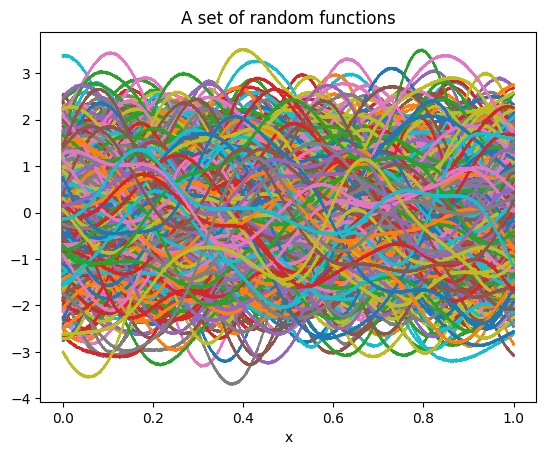

(4096, 1000)


In [2]:
# covariance function 

def k(t, l):

  val = np.exp( - ( (t**2)/(2*l**2) ) )

  return val

N_grid = 2**12

grid = np.linspace(0, 1, N_grid)

# f_vals = np.asmatrix(f(grid))

# construct covariance matrix 
l = 0.1

dist = distance_matrix(np.transpose(np.asmatrix(grid)), np.transpose(np.asmatrix(grid)))

C = k(dist, l)
nugget = 1e-4*np.identity(C.shape[0])

CC = np.linalg.cholesky( C  + nugget)

N_samples = 1000 # number of random functions we want

data = []
for i in range(N_samples):
  
  sample = np.dot(CC,np.random.randn(N_grid,1)) 

  data.append(sample)

  plt.plot(grid, sample)

data = np.transpose(np.squeeze(np.asarray(data)))

plt.xlabel('x')

plt.title('A set of random functions')

plt.show()

print(data.shape)

## Part II:

The following block of code helps you load the video file, convert it to grayscale, and rescale it as needed to speed up code developemtn. You need to install opencv. 


In [3]:
# pip install opencv-python

In [3]:
import cv2 as cv

Reading video file


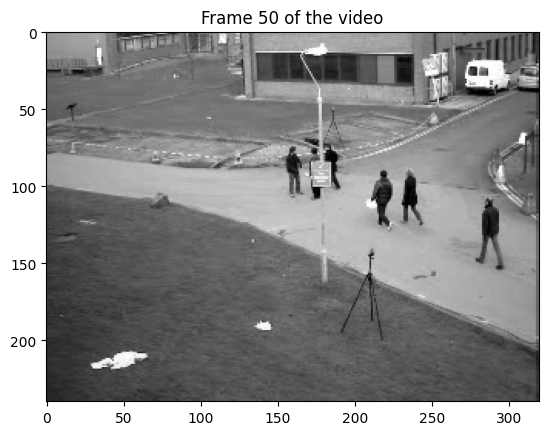

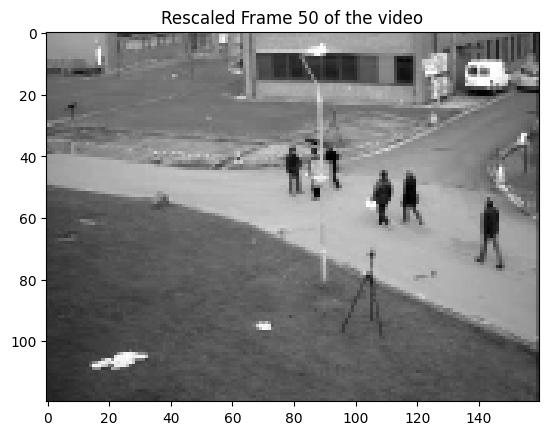

Finished reading 794 frames


In [4]:
cap = cv.VideoCapture('./Video.avi')

# check if video opened successfully
if (cap.isOpened()== False): 
  print("Error opening video stream or file")
  
print(f"Reading video file")
frame_count = 0


# Import video as well as rescaled version for easier processing


#nf = 300 # limit to 300 frames for faster processing
nf = int(cap.get(7)) # number of frames 
nx, ny = int(cap.get(3)), int(cap.get(4))

video = np.zeros( (nf, ny, nx) )

ratio = 0.5 # rescaling factor

nx_rescaled, ny_rescaled = int(ratio*nx), int(ratio*ny)

video_rescaled = np.zeros( (nf, ny_rescaled, nx_rescaled) )


while frame_count < nf:
  
  ret, frame = cap.read()
  if ret == True:

    video[frame_count, :, :] = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

    video_rescaled[frame_count, :, :] = cv.resize( cv.cvtColor(frame, cv.COLOR_BGR2GRAY), (nx_rescaled, ny_rescaled) )

    if frame_count == 50: # display frame 50
      plt.imshow(video[frame_count, :, :], cmap = 'gray')
      plt.title('Frame 50 of the video')
      plt.show()

      plt.imshow(video_rescaled[frame_count, :, :], cmap = 'gray')
      plt.title('Rescaled Frame 50 of the video')
      plt.show()
      
    frame_count += 1

  else:
    break
  
# Release the video capture object
cap.release()
cv.destroyAllWindows()
print(f"Finished reading {frame_count} frames")

In [5]:
def randomized_range_finder(X, k, p):
    m, n = X.shape[0], X.shape[1]
    W = np.random.normal(size=(n, (k+p)))
    Y = X @ W
    Q, _ = np.linalg.qr(Y)
    return Q

In [6]:
def randomized_range_finder_power(X, k, p):
    m, n = X.shape
    W = np.random.normal(size=(n, k+p))
    Y = X @ W  
    for _ in range(2):
        Q, _ = np.linalg.qr(Y)
        Z = X.T @ Q
        Y = X @ Z
    Q, _ = np.linalg.qr(Y)
    return Q

In [7]:
def randomized_svd(X, Q, k, p):
    B = Q.T @ X
    U_hat, S_hat, Vt_hat = np.linalg.svd(B, full_matrices=False)
    U = Q @ U_hat
    return U[:, :k], S_hat[:k], Vt_hat[:k, :]

In [52]:
def runner_with_power_method():
    k_s = [5, 10, 20]
    p_s = [0, 5, 10]
    itr_count = 10
    for k in k_s:
        U, S, Vt = np.linalg.svd(data)
        for p in p_s:
            print(f'parameters k: {k} p: {p}')
            errors = np.zeros(itr_count)
            for i in range(itr_count):
                X = data
                Q = randomized_range_finder_power(X, k, p)
                u, s, vt = randomized_svd(X, Q, k)
                error_norm = np.linalg.norm((X - (u @ np.diag(s) @ vt))) / np.linalg.norm(X)
                errors[i] = error_norm
            error_mean = np.mean(errors)
            error_std_dev = np.std(errors)
            print(f'error mean: {error_mean} error std dev: {error_std_dev}')

def runner():
    k_s = [5, 10, 20]
    p_s = [0, 5, 10]
    itr_count = 10
    for k in k_s:
        U, S, Vt = np.linalg.svd(data)
        for p in p_s:
            print(f'parameters k: {k} p: {p}')
            errors = np.zeros(itr_count)
            for i in range(itr_count):
                X = data
                Q = randomized_range_finder(X, k, p)
                u, s, vt = randomized_svd(X, Q, k)
                error_norm = np.linalg.norm((X - (u @ np.diag(s) @ vt))) / np.linalg.norm(X)
                errors[i] = error_norm
            error_mean = np.mean(errors)
            error_std_dev = np.std(errors)
            print(f'error mean: {error_mean} error std dev: {error_std_dev}')
runner()

parameters k: 5 p: 0
error mean: 0.5899283338494132 error std dev: 0.035444609206106224
parameters k: 5 p: 5
error mean: 0.4066092179680599 error std dev: 0.014329351410167373
parameters k: 5 p: 10
error mean: 0.3796250412392686 error std dev: 0.0006995761202579138
parameters k: 10 p: 0
error mean: 0.20140933577943304 error std dev: 0.04619791096832429
parameters k: 10 p: 5
error mean: 0.07521531287755102 error std dev: 0.001962954850904203
parameters k: 10 p: 10
error mean: 0.07034422363896246 error std dev: 0.0005537439850344575
parameters k: 20 p: 0
error mean: 0.021905852392814996 error std dev: 0.0014758117836766959
parameters k: 20 p: 5
error mean: 0.017309398513066756 error std dev: 0.0006852045872760656
parameters k: 20 p: 10
error mean: 0.0153086873110488 error std dev: 0.0006285190272128357


In [78]:
def plot_frames(frames, titles):
    n = len(frames)
    rows = math.ceil(n / 3)
    fig, axs = plt.subplots(rows, 3, figsize=(12, 12 * (rows/3)), 
                            gridspec_kw={'wspace': 0.1, 'hspace': 0.1}) 
    
    idx = 0
    for ax in axs:
        if idx < n:
            ax.imshow(frames[idx], cmap='gray')
            ax.set_title(titles[idx])
            ax.axis('off')
        else:
            ax.axis('off')
        idx += 1
    
    plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
    plt.savefig("full_random_svd.png", bbox_inches='tight', pad_inches=0)
    plt.show()

In [46]:
def plot_frame(frame, title):
    plt.imshow(frame, cmap = 'gray')
    plt.title(title)
    plt.show()

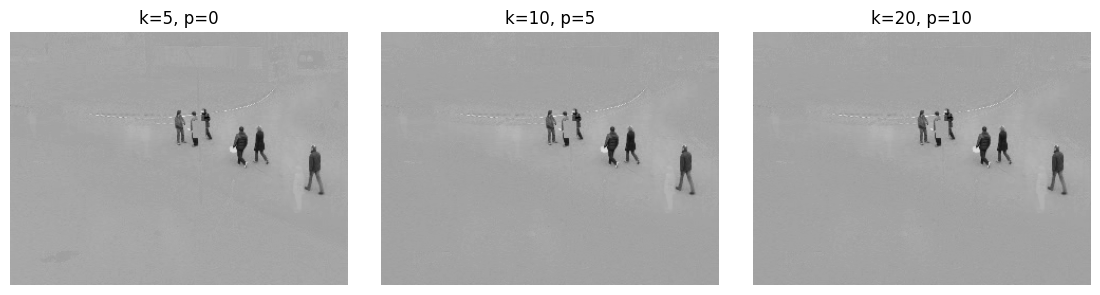

In [77]:
def remove_background_randomized(video, k=20, p=10):
    rank = 1
    nf, nx, ny = video.shape
    X = video.reshape(nf, nx * ny)
    Q = randomized_range_finder(X, k, p)
    u, s, vt = randomized_svd(X, Q, k)
    background_flat = u[:, :rank] @ np.diag(s[:rank]) @ vt[:rank, :]
    person_flat = X - background_flat
    final_video = person_flat.reshape(nf, nx, ny)
    return final_video

final_video_1 = remove_background_randomized(video, k=5, p=0)
final_video_2 = remove_background_randomized(video, k=10, p=5)
final_video_3 = remove_background_randomized(video, k=20, p=10)
plot_frames([final_video_1[50], final_video_2[50], final_video_3[50]], ["k=5, p=0", "k=10, p=5", "k=20, p=10"])

svd execution time: 0.8891349579207599 seconds. use_randomized_svd: True
svd execution time: 12.8103166250512 seconds. use_randomized_svd: False
error_norm:0.11840449148331134


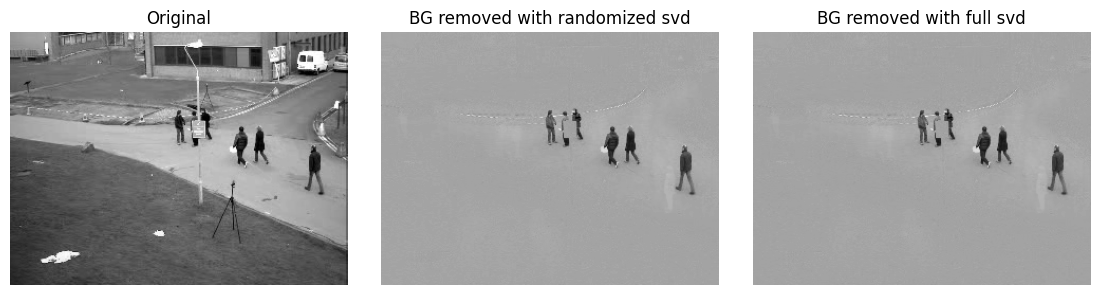

In [83]:
def remove_background(video, use_randomized_svd=True, k=20, p=10):
    rank = 1
    nf, nx, ny = video.shape
    X = video.reshape(nf, nx * ny)
    u, s, vt = None, None, None
    start = time.perf_counter()
    if use_randomized_svd:
        Q = randomized_range_finder(X, k, p)
        u, s, vt = randomized_svd(X, Q, k)
    else:
        u, s, vt = np.linalg.svd(X, full_matrices=False)
    end = time.perf_counter()
    background_flat = u[:, :rank] @ np.diag(s[:rank]) @ vt[:rank, :]
    person_flat = X - background_flat
    final_video = person_flat.reshape(nf, nx, ny)
    return final_video, end-start

use_randomized_svd = True
final_video_randomized, duration_randomized = remove_background(video, use_randomized_svd, k=20, p=10)
print(f'svd execution time: {duration_randomized} seconds. use_randomized_svd: {use_randomized_svd}')
use_randomized_svd = False
final_video, duration = remove_background(video, use_randomized_svd)
print(f'svd execution time: {duration} seconds. use_randomized_svd: {use_randomized_svd}')
error = np.linalg.norm(final_video - final_video_randomized) / np.linalg.norm(final_video_randomized)
print(f'error_norm:{error}')
plot_frames([video[50], final_video_randomized[50], final_video[50]], ["Original", "BG removed with randomized svd", "BG removed with full svd"])

In [47]:
output_file = 'ghost_video.avi'
fps = 30
height, width = nx, ny
fourcc = cv.VideoWriter_fourcc(*'MJPG')
out = cv.VideoWriter(output_file, fourcc, fps, (width, height))

print(f"Rendering {nf} frames to {output_file}...")

for i in range(nf):
    frame = final_video[i]
    frame_norm = cv.normalize(frame, None, 0, 255, cv.NORM_MINMAX)
    frame_uint8 = frame_norm.astype(np.uint8)
    frame_bgr = cv.cvtColor(frame_uint8, cv.COLOR_GRAY2BGR)
    out.write(frame_bgr)
out.release()
print("Done! Go open output.avi")

Rendering 795 frames to ghost_video.avi...
Done! Go open output.avi
